# 1. What is edge detection?

An edge is a location in an image where pixel intensity changes significantly over a short distance.

Imagine a black letter printed on white paper. The letter's interior is mostly dark, the background is mostly bright, and the boundary between them has a strong intensity change. Edge detection tries to locate that boundary.

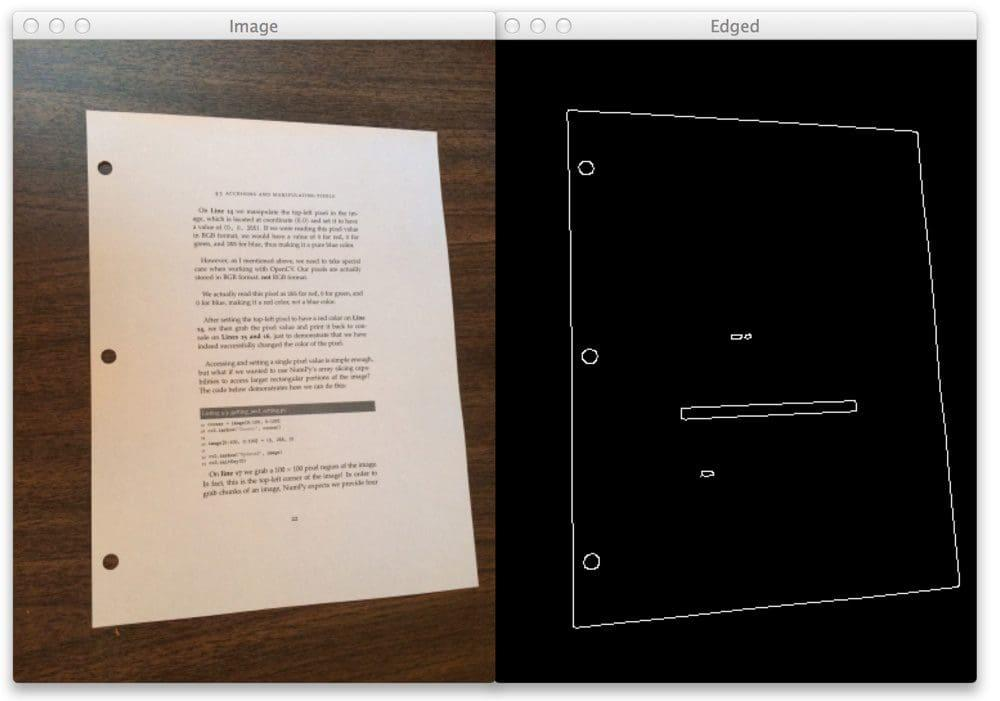


Edge detection is useful for:

- Detecting document boundaries and correcting perspective.
- Finding object outlines.
- Segmenting images.
- Measuring shapes and contours.
- Identifying cracks or defects in manufacturing.
- Preprocessing images for computer vision models.


# 2. Image gradients

### Intuition

Suppose pixel brightness changes as you move across an image:

`10 → 10 → 12 → 100 → 220 → 222`

The change is small in the first region, large around the transition, and small again afterward. The large change suggests an edge.

A gradient describes how quickly intensity changes and in which direction.

For a grayscale image \\(I(x,y)\\), the gradient has two components:

\\[ G_x=\frac{\partial I}{\partial x}, \qquad G_y=\frac{\partial I}{\partial y} \\]

- \\(G_x\\): intensity change horizontally.
- \\(G_y\\): intensity change vertically.

The gradient magnitude tells us the strength of the change:

\\[ G=\sqrt{G_x^2+G_y^2} \\]

The gradient direction is:

\\[ \theta=\operatorname{atan2}(G_y,G_x) \\]

A large magnitude indicates a strong intensity transition; the direction indicates the direction of increasing intensity, which is perpendicular to an ideal straight edge.

### Example

Imagine a vertical black-to-white boundary. As you move horizontally across it, intensity changes sharply, so \\(G_x\\) is large. Moving vertically along a uniform part of the boundary changes little, so \\(G_y\\) is small.

This is why gradients help locate edges.

# 3. Sobel operator

Sobel is an operator that estimates the first derivatives of an image. It uses small convolution kernels to measure horizontal and vertical intensity changes.

### Sobel kernels

Horizontal derivative:

\\[ K_x= \begin{bmatrix} -1&0&1\\\ -2&0&2\\\ -1&0&1 \end{bmatrix} \\]

Vertical derivative:

\\[ K_y= \begin{bmatrix} -1&-2&-1\\\ 0&0&0\\\ 1&2&1 \end{bmatrix} \\]

OpenCV applies these kernels to calculate \\(G_x\\) and \\(G_y\\). The center row or column has greater weight, and the kernel also performs a little smoothing in the perpendicular direction.



### How to interpret the output

- Sobel X: highlights changes across the horizontal direction, so vertical boundaries tend to respond strongly.
- Sobel Y: highlights changes across the vertical direction, so horizontal boundaries tend to respond strongly.
- Magnitude: combines both directions to show overall gradient strength.

One detail: the derivative sign indicates the direction of intensity change, but `convertScaleAbs()` displays absolute values. Therefore, the displayed X and Y images do not preserve that sign.

### When should you use Sobel?

Use it when you want to measure edge strength or direction, or when you need gradient information for another algorithm. It is also useful for inspecting text boundaries in your document-enhancement project.

# 4. Laplacian operator

The Laplacian uses second-order derivatives. Rather than directly measuring the rate of intensity change, it measures how that rate changes across neighboring pixels.

Its continuous mathematical definition is:

\\[ \nabla^2 I= \frac{\partial^2 I}{\partial x^2} + \frac{\partial^2 I}{\partial y^2} \\]

A common discrete approximation uses this kernel:

\\[ K= \begin{bmatrix} 0&1&0\\\ 1&-4&1\\\ 0&1&0 \end{bmatrix} \\]

The overall sign can be reversed without changing the core idea.

### Intuition

Imagine crossing from a white background into a black letter. The first derivative changes around the boundary. The second derivative responds to how that first derivative changes, often producing positive and negative responses around the transition.

This makes the Laplacian sensitive to fine detail, but also to noise.



### Sobel vs. Laplacian

| Property          | Sobel                              | Laplacian                                       |
| ----------------- | ---------------------------------- | ----------------------------------------------- |
| Derivative order  | First                              | Second                                          |
| Direction         | Calculates X and Y separately      | Combines changes in both directions             |
| Output            | Gradient and direction information | Second-order response                           |
| Noise sensitivity | Sensitive to noise                 | Often more sensitive to noise                   |
| Typical use       | Edge strength and orientation      | Fine-detail analysis, sharpening, edge analysis |

Important: the Laplacian output is not automatically a clean binary edge map. Thresholding or further processing may be necessary. Also, Laplacian variance is sometimes used as a rough sharpness measure, but it is not a reliable universal blur detector by itself.

# 5. Canny edge detection

Canny is a multi-stage edge-detection algorithm designed to produce relatively thin, well-localized edges while suppressing many weak or irrelevant responses.

It is more than a single convolution kernel.


Step 1 — Gaussian smoothing

Reduces noise before calculating gradients. Too much smoothing can erase fine details.

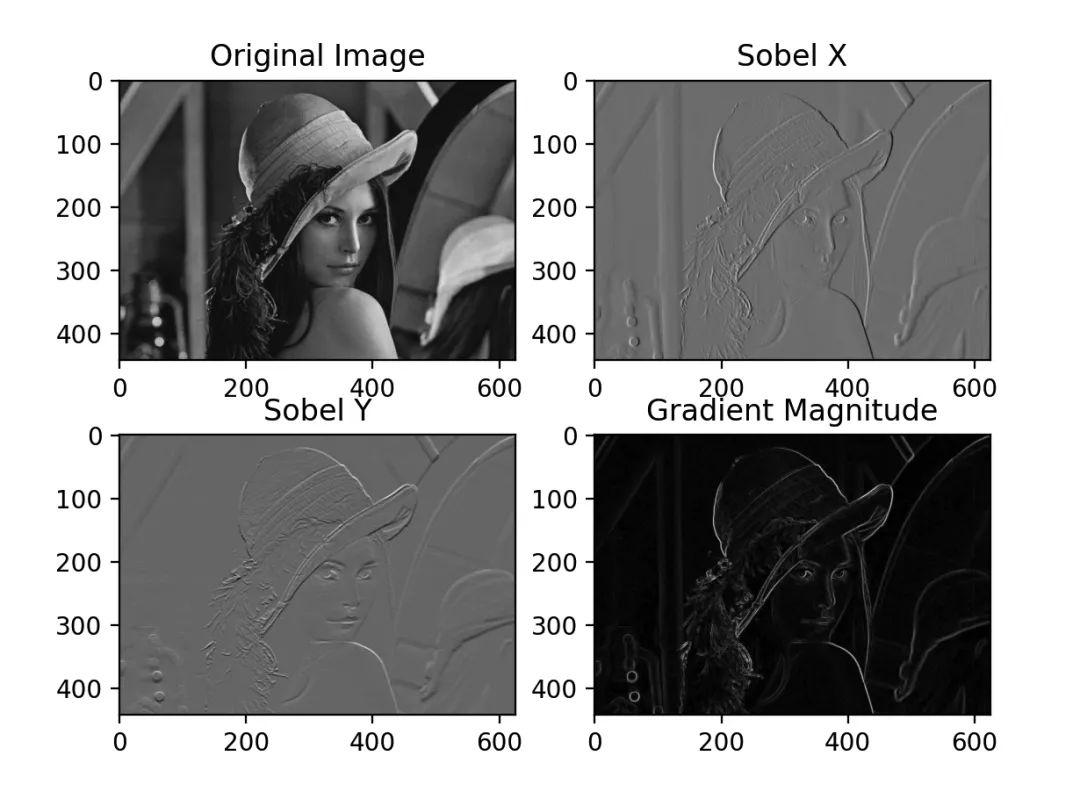

Step 2 — Gradient calculation

Estimates edge strength and orientation, typically using derivative filters.

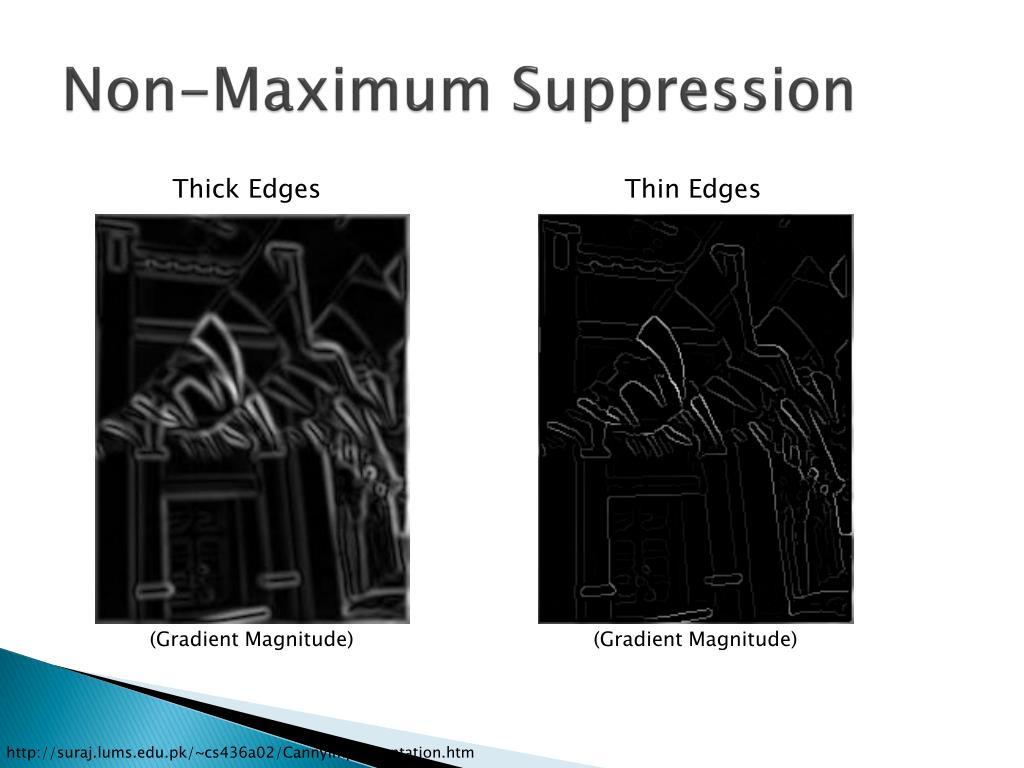

Step 3 — Non-maximum suppression

Keeps local maxima along the gradient direction, thinning broad responses into narrow edges.

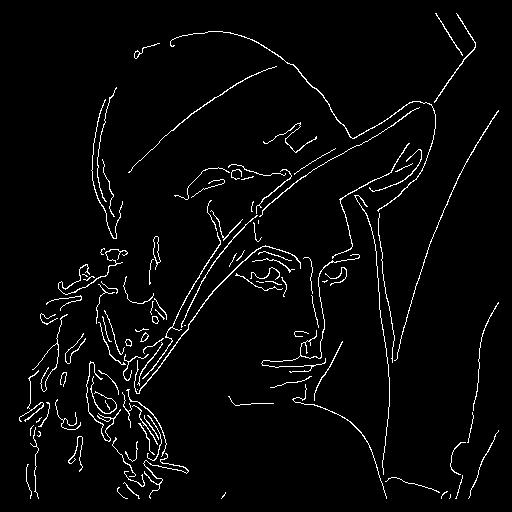

Step 4 — Double thresholding and hysteresis

Strong edges are retained; weaker edges are retained when connected to strong edges through the algorithm's edge-tracking process.



The two thresholds have different roles:

- `threshold1=50`: lower threshold.
- `threshold2=150`: upper threshold.

These are starting values, not universal settings. Lowering them generally allows more weak edges to survive; raising them generally produces fewer edges. The best values depend on the image, noise level, and the structures you want to retain.

For noisy document images, try Gaussian smoothing before Canny. For salt-and-pepper noise, a median filter may be a better initial step.



## 7. Which one should you use in your project?

| Goal                                         | Good starting point                                       |
| -------------------------------------------- | --------------------------------------------------------- |
| Find document or page boundaries             | Canny, followed by contour and geometric analysis         |
| Measure edge strength and orientation        | Sobel                                                     |
| Analyze fine intensity transitions           | Laplacian                                                 |
| Estimate blur or sharpness                   | Laplacian-based statistics, combined with other evidence  |
| Locate text and object outlines              | Canny or Sobel, depending on the task                     |
| Find page corners for perspective correction | Canny plus contour detection and quadrilateral validation |

Remember: edge detection finds boundaries; it does not automatically understand what those boundaries represent. For example, Canny may detect the borders of individual letters, but you still need additional logic to identify the document's four outer corners.

---

# Setup and load the image

Image shape: (1000, 800, 3)
Grayscale shape: (1000, 800)
Data type: uint8


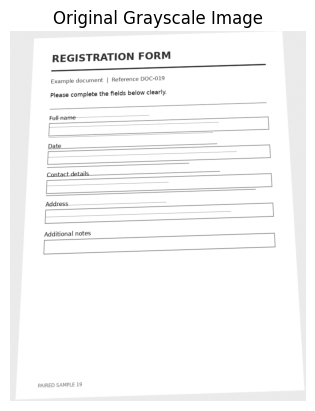

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt 

image_path = 'images/02_image.png'

image = cv2.imread(image_path)
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

gray = cv2.cvtColor(image,cv2.COLOR_RGB2GRAY)

print("Image shape:", image.shape)
print("Grayscale shape:", gray.shape)
print("Data type:", gray.dtype)

plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

# Image gradients and Sobel

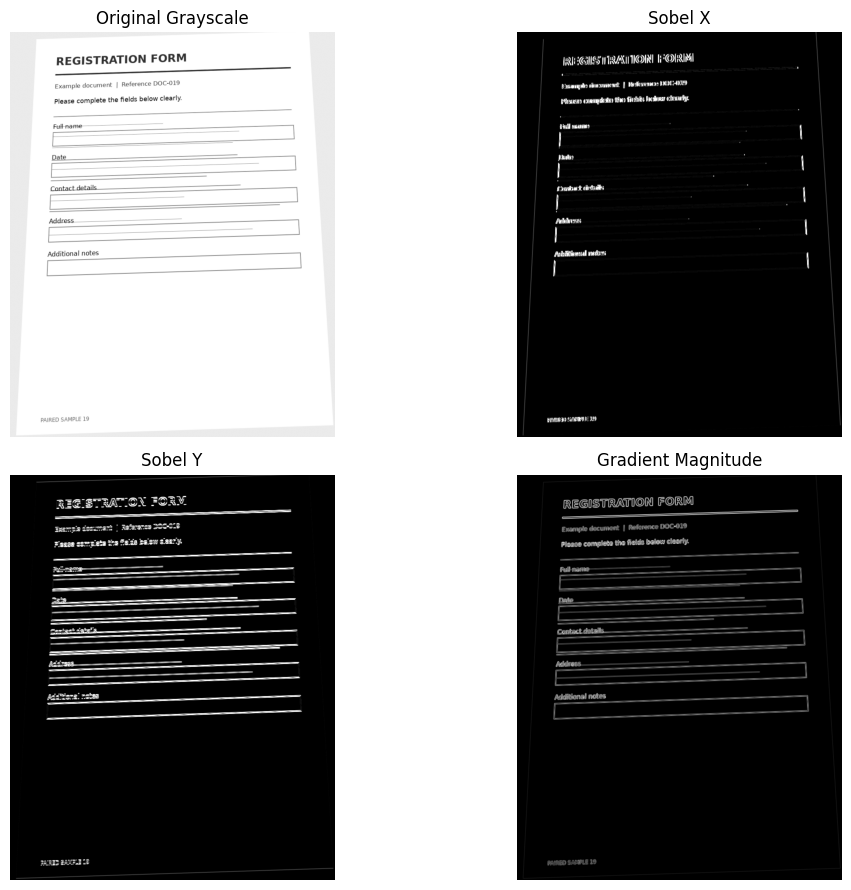

In [13]:
# First derivatives
sobel_x = cv2.Sobel(
    gray, cv2.CV_64F, 1, 0, ksize=3
)

sobel_y = cv2.Sobel(
    gray, cv2.CV_64F, 0, 1, ksize=3
)

# Gradient magnitude
gradient_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)

# Convert to displayable uint8
gradient_display = cv2.normalize(
    gradient_magnitude, None, 0, 255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Absolute directional responses
sobel_x_display = cv2.convertScaleAbs(sobel_x)
sobel_y_display = cv2.convertScaleAbs(sobel_y)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

images = [
    (gray, "Original Grayscale"),
    (sobel_x_display, "Sobel X"),
    (sobel_y_display, "Sobel Y"),
    (gradient_display, "Gradient Magnitude")
]

for ax, (img, title) in zip(axes.ravel(), images):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Laplacian edge detection

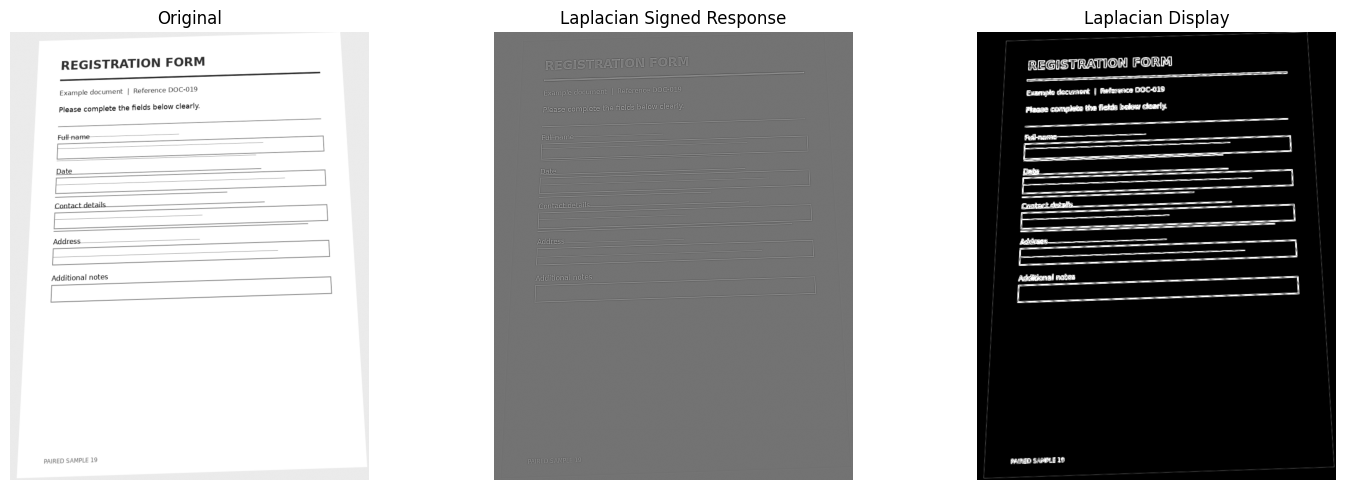

In [15]:
laplacian = cv2.Laplacian(
    gray,
    cv2.CV_64F,
    ksize=3
)

laplacian_display = cv2.convertScaleAbs(laplacian)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original")

axes[1].imshow(laplacian, cmap="gray")
axes[1].set_title("Laplacian Signed Response")

axes[2].imshow(laplacian_display, cmap="gray")
axes[2].set_title("Laplacian Display")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Canny edge detection

# Canny Edge Detection

## Definition
Canny is a multi-stage edge detection algorithm that identifies significant intensity boundaries while reducing unwanted edges.

## Working Steps
1. **Gaussian Smoothing:** Reduces noise.
2. **Gradient Calculation:** Estimates edge strength and direction.
3. **Non-Maximum Suppression:** Thins edges.
4. **Double Thresholding:** Classifies strong, weak, and rejected edge candidates.
5. **Hysteresis Tracking:** Retains weak edges connected appropriately to strong edges.

## OpenCV Implementation

```python
canny_50_150 = cv2.Canny(gray, 50, 150)
canny_100_200 = cv2.Canny(gray, 100, 200)
canny_150_250 = cv2.Canny(gray, 150, 250)
```

- First value: Lower threshold.
- Second value: Upper threshold.

## Effect of Thresholds

| Thresholds | Typical effect |
|---|---|
| `(50, 150)` | More sensitive; detects weaker edges and potentially more noise |
| `(100, 200)` | Moderate sensitivity |
| `(150, 250)` | Less sensitive; weak edges may disappear |

Higher thresholds generally produce fewer detected edges, depending on the image.

## Applications
- Document boundary detection
- Object outline detection
- Contour detection
- Image segmentation
- Computer vision preprocessing

## Important Note
Canny detects edges but does not identify what they represent. Thresholds should be selected based on image quality and the application.


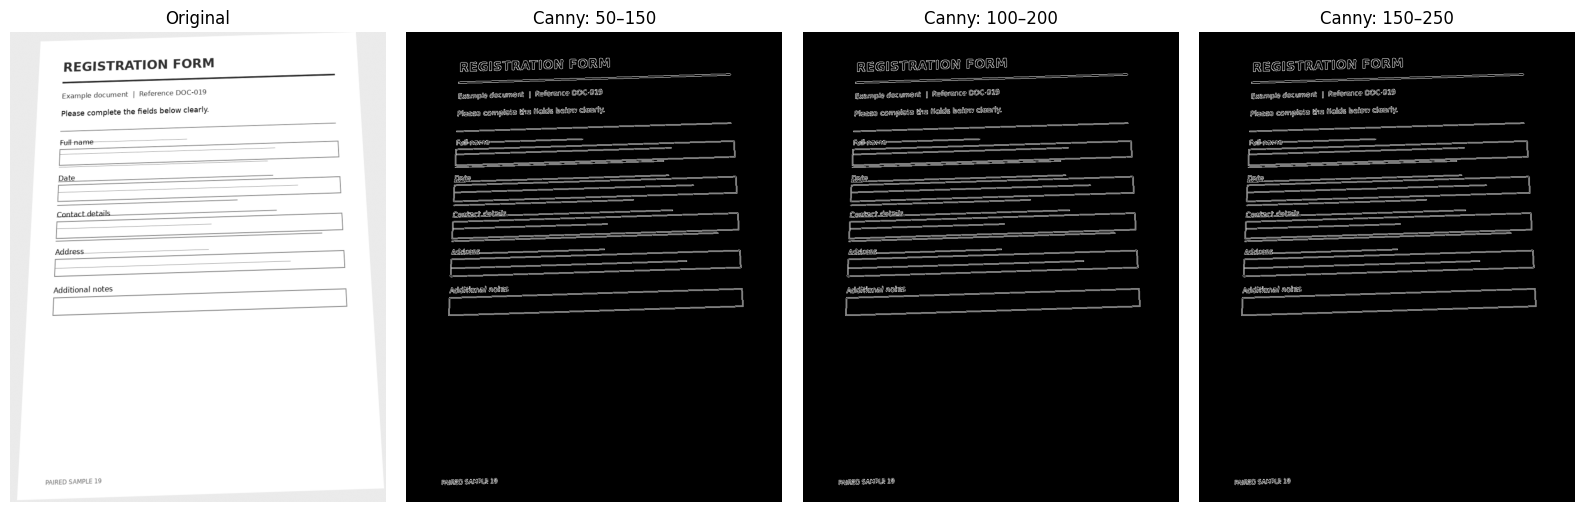

In [16]:
canny_50_150 = cv2.Canny(gray, 50, 150)
canny_100_200 = cv2.Canny(gray, 100, 200)
canny_150_250 = cv2.Canny(gray, 150, 250)

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

images = [
    (gray, "Original"),
    (canny_50_150, "Canny: 50–150"),
    (canny_100_200, "Canny: 100–200"),
    (canny_150_250, "Canny: 150–250")
]

for ax, (img, title) in zip(axes, images):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Comparison

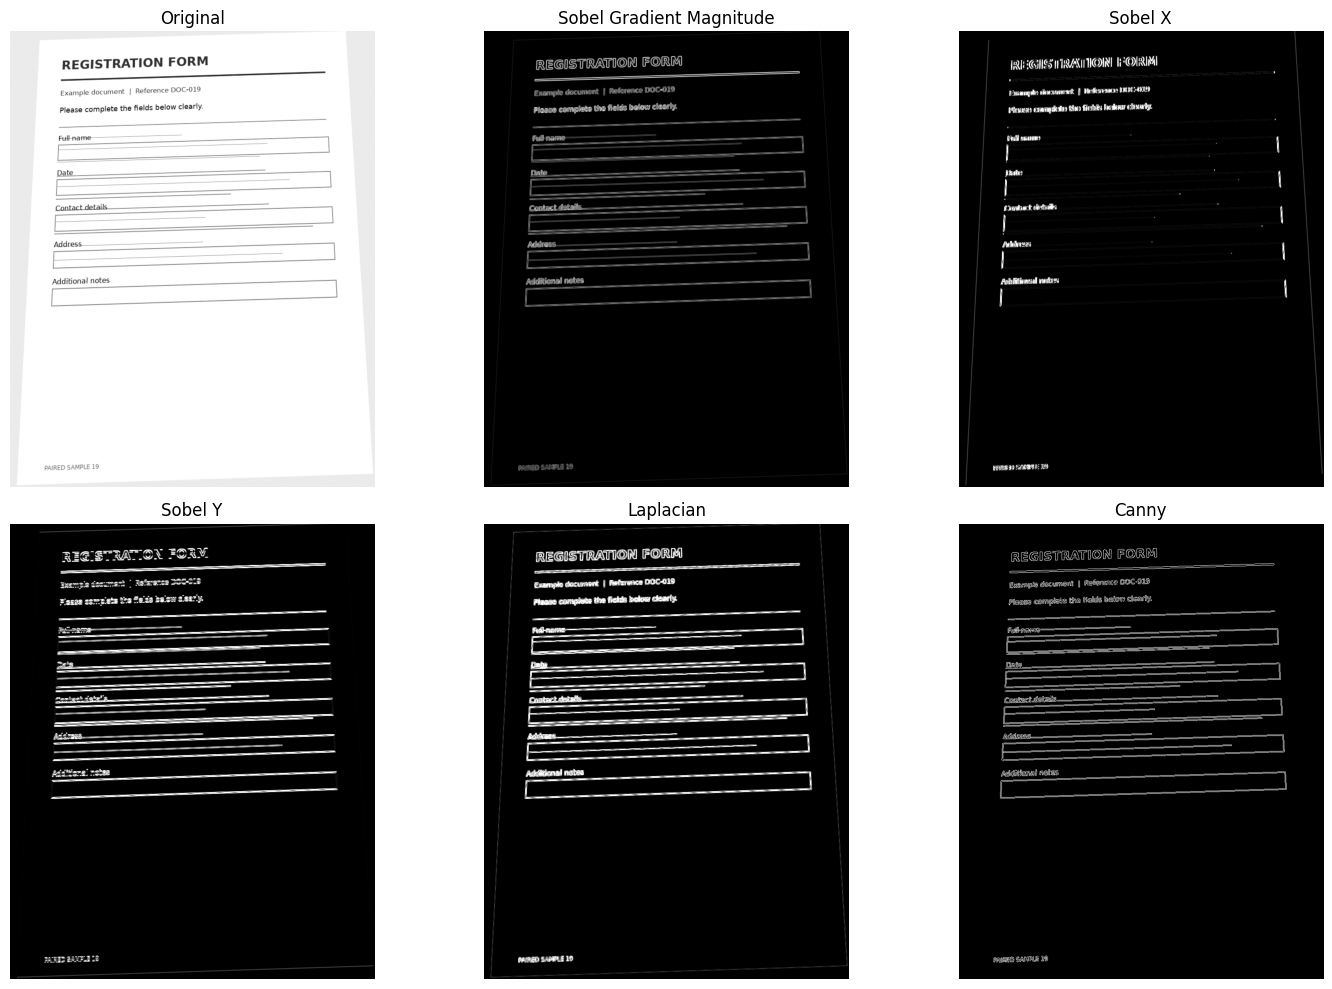

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

comparison = [
    (gray, "Original"),
    (gradient_display, "Sobel Gradient Magnitude"),
    (sobel_x_display, "Sobel X"),
    (sobel_y_display, "Sobel Y"),
    (laplacian_display, "Laplacian"),
    (canny_50_150, "Canny")
]

for ax, (img, title) in zip(axes.ravel(), comparison):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.savefig('images/1_Edge_Detection.jpg')
plt.show()